In [1]:
import numpy as np
import matplotlib.pyplot as plt
import itertools
import pandas as pd

### Read normal vectors to basal plane for the grains of interest:
#### 1- In Paraview, click in the corresponding grain and read voxel info "normal_vector_to_basal_plane" 
#### 2- Insert below the result with the format [Y, -Z, X]

In [2]:
# c-axis vectors of grains forming OR with hydrides, obtained from dream3d pipeline:
caxis_OR_vector= {
    'Hydride 1-p1': [-0.535, -0.864, 0.243],
    'Hydride 1-p2': [-0.535, -0.864, 0.243],
    'Hydride 2-p1': [-0.074, -0.630, -0.773],
    'Hydride 2-p2': [-0.074, -0.630, -0.773],
    'Hydride 3': [-0.257, 0.515, -0.129],
    'Hydride 4-p1':[-0.257, 0.515, -0.129],
    'Hydride 4-p2':[-0.257, 0.515, -0.129],
    'Hydride 5-p1':[-0.278, -0.555, -0.278],
    'Hydride 5-p2':[-0.278, -0.555, -0.278],
    'Hydride 6':[-0.281, 0.952, -0.073],
    'Hydride 7':[-0.358, 0.963, 0.178],
    'Hydride 8':[-0.005, -0.251, -0.997],
    'Hydride 9':[-0.206, 0.337, 0.963],
    'Hydride 10':[-0.448, 0.533, 0.595]
}

In [3]:
# Vectors perpendicular to the planes fitted to GB, measured in Paraview:
normal_vector= {
    'Hydride 1-p1': [0.950, 0.175, 0.258],
    'Hydride 1-p2': [0.984, 0.016, 0.176],
    'Hydride 2-p1': [-0.661, -0.113, 0.741],
    'Hydride 2-p2': [-0.526, -0.496, 0.691],
    'Hydride 3':[0.456, -0.872, 0.182],
    'Hydride 4-p1':[0.679, 0.732, -0.057],
    'Hydride 4-p2':[0.380, 0.899, -0.219],
    'Hydride 5-p1':[0.249, -0.954, -0.169],
    'Hydride 5-p2':[0.178, -0.961, -0.212],
    'Hydride 6':[-0.365,0.037,0.930],
    'Hydride 7':[-0.019, 0.118, 0.993],
    'Hydride 8':[0.706, 0.113, 0.699],
    'Hydride 9':[0.411, 0.165, 0.897 ],
    'Hydride 10':[0.091, 0.646, -0.758]
}

In [4]:
# Function to calculate the angle between two vectors:

def angle(n, b): # θ=arctan2(∥n×b∥,|n⋅b|)
    dot = np.dot(n, b)
    normcross = np.linalg.norm(np.cross(n, b))
    dot = abs(dot)  # make angle insensitive to sign flips
    # Use atan2 for better numerical stability than arccos
    return np.degrees(np.arctan2(normcross, dot))

In [5]:
# Calculate angle between c-axis vector and normal vector to GBs:
angles_OR = {}
for h in normal_vector:
    angles_OR[h] = int(np.round(angle(caxis_OR_vector[h], normal_vector[h])))

angles_OR

{'Hydride 1-p1': 55,
 'Hydride 1-p2': 62,
 'Hydride 2-p1': 63,
 'Hydride 2-p2': 79,
 'Hydride 3': 2,
 'Hydride 4-p1': 69,
 'Hydride 4-p2': 48,
 'Hydride 5-p1': 42,
 'Hydride 5-p2': 37,
 'Hydride 6': 86,
 'Hydride 7': 73,
 'Hydride 8': 45,
 'Hydride 9': 37,
 'Hydride 10': 81}

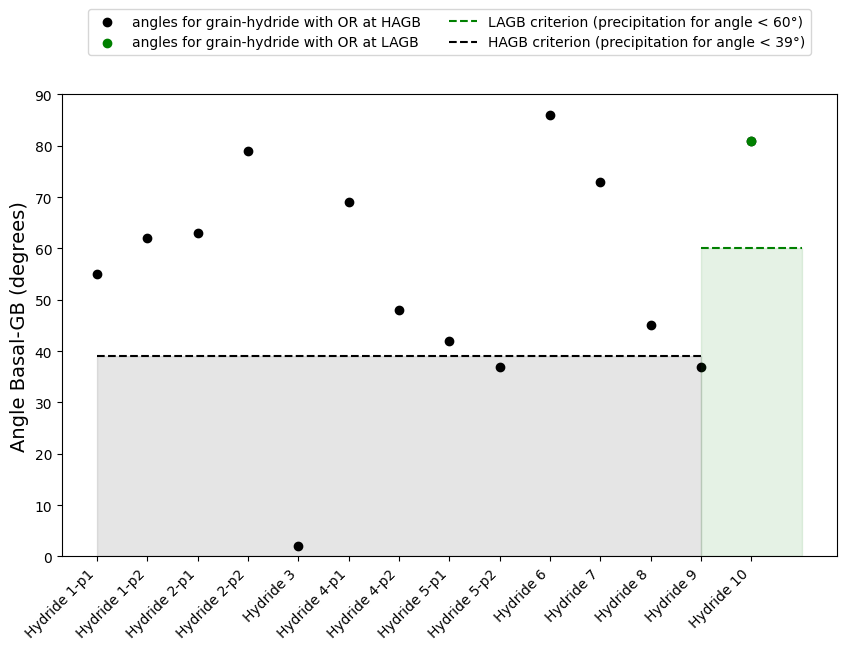

In [6]:
# Plotting the angles and comparing with criteria for preferred hydride precipitation:

labels = list(angles_OR.keys())
values = list(angles_OR.values())

plt.figure(figsize=(10,6))
plt.scatter(labels, values, color='black', label='angles for grain-hydride with OR at HAGB')
plt.scatter(labels[-1], values[-1], color='green',label='angles for grain-hydride with OR at LAGB') # only the last hydride was at LAGB

plt.hlines(y=60, xmin=12, xmax=14, color='green', linestyle='--', label='LAGB criterion (precipitation for angle < 60°)')
plt.hlines(y=39, xmin=0, xmax=len(labels)-2, color='black', linestyle='--', label='HAGB criterion (precipitation for angle < 39°)')
plt.fill_between(range(12,15), 0, 60, color='green', alpha=0.1)
plt.fill_between(range(len(labels)-1), 0, 39, color='black', alpha=0.1)
plt.ylim(0, 90)

plt.xticks(rotation=45, ha='right')
plt.ylabel('Angle Basal-GB (degrees)', fontsize=14)
plt.legend(loc='upper center', bbox_to_anchor=(0.5, 1.20), ncol=2)


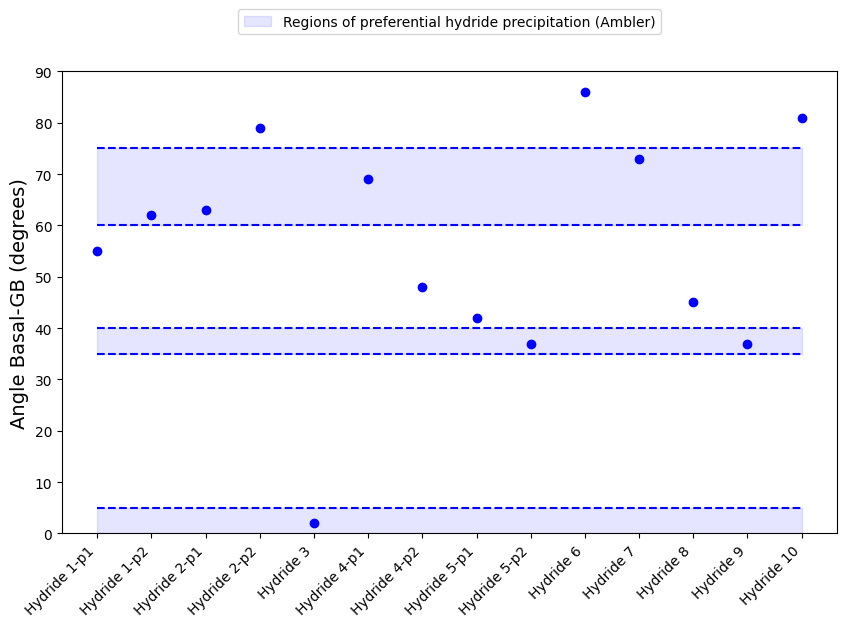

In [7]:
# Plotting the angles and comparing with criteria for preferred hydride precipitation:

labels = list(angles_OR.keys())
values = list(angles_OR.values())

plt.figure(figsize=(10,6))
plt.scatter(labels, values, color='blue')

plt.hlines(y=75, xmin=0, xmax=len(labels)-1, color='blue', linestyle='--')
plt.hlines(y=60, xmin=0, xmax=len(labels)-1, color='blue', linestyle='--')
plt.hlines(y=40, xmin=0, xmax=len(labels)-1, color='blue', linestyle='--')
plt.hlines(y=35, xmin=0, xmax=len(labels)-1, color='blue', linestyle='--' )
plt.hlines(y=5, xmin=0, xmax=len(labels)-1, color='blue', linestyle='--')

plt.fill_between(range(len(labels)), 60, 75, color='blue', alpha=0.1, label='Regions of preferential hydride precipitation (Ambler)')
plt.fill_between(range(len(labels)), 35, 40, color='blue', alpha=0.1)
plt.fill_between(range(len(labels)), 0, 5, color='blue', alpha=0.1)

plt.ylim(0, 90)

plt.xticks(rotation=45, ha='right')
plt.ylabel('Angle Basal-GB (degrees)', fontsize=14)
plt.legend(loc='upper center', bbox_to_anchor=(0.5, 1.15), ncol=2)

### Calculate angular deviation to find the tolerance of the plane fitting to GB measurements

In [8]:
# The plane fitting was repeated 5 times for hydride 8:
vectors_hyd8 = {"v1" : np.array([0.706, 0.113, 0.699]),
           "v2" : np.array([0.691, 0.031, 0.723]),
           "v3" : np.array([0.681, 0.123, 0.721]),
           "v4" : np.array([0.689, 0.046, 0.723]),
           "v5" : np.array([0.684, 0.092, 0.724]),
}

In [9]:
# Compute all pairwise combinations
results = []
for (name1, vec1), (name2, vec2) in itertools.combinations(vectors_hyd8.items(), 2):
    angles = angle(vec1, vec2)
    results.append((name1, name2, np.round(angles,2)))

df = pd.DataFrame(results, columns=["Vector 1", "Vector 2", "Angle (degrees)"])

df

,Vector 1,Vector 2,Angle (degrees)
0,v1,v2,4.97
1,v1,v3,1.99
2,v1,v4,4.19
3,v1,v5,2.26
4,v2,v3,5.31
5,v2,v4,0.87
6,v2,v5,3.52
7,v3,v4,4.44
8,v3,v5,1.79
9,v4,v5,2.65


## 2D vs 3D plane fitting to GB

In [10]:
# Plane fitting to GB assuming it is perpendicular to the plane:
GB_planefitting_2D = {
    'Hydride 8':[0.0145,0.0598, 0.998],
    'Hydride 9':[0.0190,0.136, 0.990],
    'Hydride 10':[0.0997, -0.641, 0.761]
}

# Plane fitting to GB using 3D data:
GB_planefitting_3D = {
    'Hydride 8':[0.706, 0.113, 0.699],
    'Hydride 9':[0.411, 0.165, 0.897 ],
    'Hydride 10':[0.091, 0.646, -0.758]
}

# c-axis vectors of grains forming OR with hydrides, obtained from dream3d pipeline:
caxis_OR_vector = {
    'Hydride 8':[-0.002, -0.489, -0.872],
    'Hydride 9':[0.242, -0.325, -0.914],
    'Hydride 10':[0.330, -0.623, -0.709]
}

In [11]:
# Calculate angle between c-axis vector and normal vector to GBs:

labels_2D = list(GB_planefitting_2D.keys())
labels_3D = list(GB_planefitting_3D.keys())

labels_2D = []
angles_2D = []

labels_3D = []
angles_3D = []

for key in caxis_OR_vector:
    angle2D = angle(GB_planefitting_2D[key], caxis_OR_vector[key])
    angle3D = angle(GB_planefitting_3D[key], caxis_OR_vector[key])
    
    if angle2D is not None:
        labels_2D.append(key)
        angles_2D.append(angle2D)
        
    if angle3D is not None:
        labels_3D.append(key)
        angles_3D.append(angle3D)

print(np.round(angles_2D))
print(np.round(angles_3D))

[26. 19. 84.]
[48. 39. 81.]


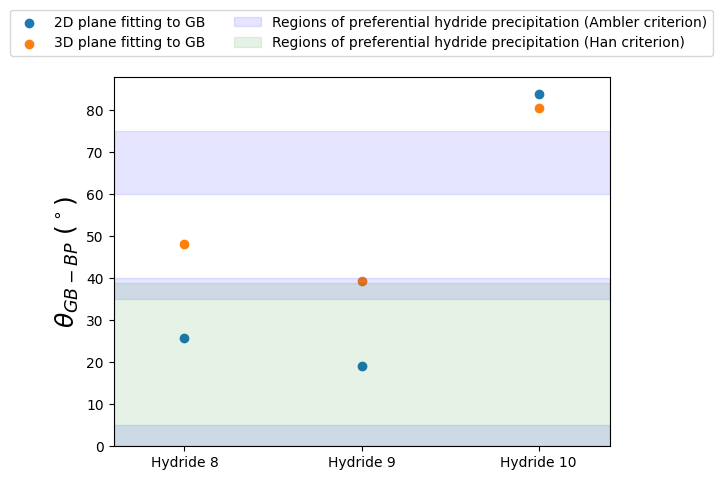

In [12]:
# Plotting the angles and comparing 2D vs 3D plane fitting for three hydrides:
plt.figure()

plt.scatter(labels_2D, angles_2D, label="2D plane fitting to GB")
plt.scatter(labels_3D, angles_3D, label="3D plane fitting to GB")

# Ambler critetion:
plt.axhspan(60, 75, color='blue', alpha=0.1, label='Regions of preferential hydride precipitation (Ambler criterion)')
plt.axhspan(35, 40, color='blue', alpha=0.1)
plt.axhspan(0, 5, color='blue', alpha=0.1)

# Han criterion:
plt.axhspan(0, 39, color='green', alpha=0.1, label='Regions of preferential hydride precipitation (Han criterion)')

plt.ylabel(r'$\theta_{GB-BP}\ (^\circ)$', fontsize=18)

plt.legend(loc='upper center', bbox_to_anchor=(0.5, 1.2), ncol=2)
plt.margins(x=0.2)

plt.ylim(bottom=0)
plt.show()